# Paper Results: FTS-ANFIS-BN Cognitive Load Pipeline

This notebook re-runs the three ablation experiments and extracts the experimental results
reported in the paper.

| Code ablation | Paper label | Description |
|---|---|---|
| `exp1` | **Exp1** | FTS → ANFIS → BN (full pipeline) |
| `exp2` | **Exp2** | FTS → ANFIS → mean fusion (no BN) |
| `exp3` | **Exp3** | FTS → FTS summary → BN (no ANFIS) |

**Preset used:** `A2_soft`  
**Seed:** 42 (fixed, not changed)  
**Threshold:** selected from OOF posteriors (not hard-coded)  
**Positive class:** TASK = 1

## Cell 1 — Import Libraries

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

print("Libraries imported successfully.")


Libraries imported successfully.


## Cell 2 — Setup Paths and Project Root

In [2]:
# ── Resolve project root ───────────────────────────────────────────────────────
# Works whether executed from the project root or from the notebooks/ sub-folder.
_here = Path(globals().get("__file__", ".")).resolve()
if (_here / "src").is_dir():
    PROJECT_ROOT = _here
elif (_here.parent / "src").is_dir():
    PROJECT_ROOT = _here.parent
else:
    PROJECT_ROOT = Path.cwd().resolve()
    # Walk up until we find the src/ directory
    for _candidate in [PROJECT_ROOT] + list(PROJECT_ROOT.parents):
        if (_candidate / "src").is_dir():
            PROJECT_ROOT = _candidate
            break

SRC_PATH     = PROJECT_ROOT / "src"
DATA_PATH    = PROJECT_ROOT / "last_30s_segments"
RESULTS_DIR  = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

# Add src/ to sys.path so fbn_pipeline can be imported
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# Create results/ directory
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"src/         : {SRC_PATH}  (exists={SRC_PATH.is_dir()})")
print(f"Data         : {DATA_PATH}  (exists={DATA_PATH.is_dir()})")
print(f"Results dir  : {RESULTS_DIR}")
print(f"Artifacts dir: {ARTIFACTS_DIR}")


Project root : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final
src/         : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\src  (exists=True)
Data         : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\last_30s_segments  (exists=True)
Results dir  : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\results
Artifacts dir: C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts


## Cell 3 — Helper Functions for Running Experiments

> **Design note:** `main.py` executes `run_single()` automatically in its `else` branch
> (both `__main__` and import-time), so it **cannot** be safely imported here.
> Instead we import the pipeline components directly from `src/fbn_pipeline` and
> replicate only the core logic of `run_single()` (CV → threshold selection → retrain/test).
> No training logic is modified and the random seed is preserved.

In [3]:
# ── Import pipeline components directly (avoids main.py auto-run side-effect) ──
from fbn_pipeline import ExperimentConfig, apply_preset, setup_seed
from fbn_pipeline.data import load_dataset
from fbn_pipeline.metrics import find_best_threshold
from fbn_pipeline.pipeline import compute_oof_metrics, retrain_and_test, run_cv

print("fbn_pipeline imported successfully.")


# ── Experiment definitions ─────────────────────────────────────────────────────
#   Preset A2_soft: n_sets=3, gaussian MF, fts_norm=row, n_rules=6,
#                   n_epochs=50, n_bins=5, alpha=0.5, bn_soft=True
#
#   Paper mapping:
#     Exp1 → ablation=exp1  (FTS → ANFIS → BN)
#     Exp2 → ablation=exp2  (FTS → ANFIS → mean fusion, no BN)
#     Exp3 → ablation=exp3  (FTS → FTS summary → BN, ANFIS bypassed)

PAPER_EXPERIMENTS: list[dict] = [
    {
        "label":         "Exp1",
        "configuration": "FTS-ANFIS-BN",
        "preset":        "A2_soft",
        "ablation":      "exp1",
        "extra_cfg":     {},
    },
    {
        "label":         "Exp2",
        "configuration": "FTS-ANFIS Mean fusion",
        "preset":        "A2_soft",
        "ablation":      "exp2",
        "extra_cfg":     {"fusion_mode_when_no_bn": "mean"},
    },
    {
        "label":         "Exp3",
        "configuration": "FTS Summary-BN",
        "preset":        "A2_soft",
        "ablation":      "exp3",
        "extra_cfg":     {"fts_summary_mode": "diag_high"},
    },
]


# ── Core runner ────────────────────────────────────────────────────────────────
def run_experiment(
    preset: str,
    ablation: str,
    extra_cfg: dict | None = None,
    data_path: Path = DATA_PATH,
    verbose: bool = True,
) -> dict:
    """
    Run a single ablation experiment end-to-end:
      1. Build config (preset + ablation override)
      2. Set random seed (from config, not changed)
      3. Load dataset
      4. GroupKFold CV → OOF posteriors
      5. Select threshold on OOF (balanced_accuracy, grid=181) — same as main.py
      6. Retrain on full train set, evaluate on held-out test set

    Returns
    -------
    dict with keys:
        oof_post, oof_y, oof_pred, oof_acc, best_thr,
        test_pred, test_post, y_test, user_test, cfg
    """
    extra_cfg = extra_cfg or {}

    # Build config exactly as main.py does
    cfg = ExperimentConfig(data_path=str(data_path))
    cfg = apply_preset(cfg, preset)
    cfg = cfg.merged(ablation=ablation, **extra_cfg)

    # Preserve seed — do not change
    setup_seed(cfg.seed)

    dataset = load_dataset(data_path)

    if verbose:
        print(f"  [CV]      ablation={ablation}, preset={preset}, seed={cfg.seed}, "
              f"k_folds={cfg.k_folds}")

    oof_post, oof_y, _ = run_cv(
        dataset.X_train, dataset.y_train, dataset.user_train, cfg
    )

    best_thr, thr_score = find_best_threshold(
        oof_y, oof_post,
        metric=cfg.threshold_metric,
        n_grid=cfg.threshold_grid,
    )
    oof_pred = (oof_post >= best_thr).astype(int)
    oof_acc  = float(accuracy_score(oof_y, oof_pred))

    if verbose:
        print(f"  [THR]     best_thr={best_thr:.4f}  "
              f"({cfg.threshold_metric}={thr_score:.4f})")

    test_pred, test_post, _test_metrics, _models = retrain_and_test(
        dataset.X_train, dataset.y_train,
        dataset.X_test,  dataset.y_test,
        best_thr, cfg,
    )

    if verbose:
        print(f"  [TEST]    acc={accuracy_score(dataset.y_test, test_pred):.4f}")

    return {
        "oof_post":  oof_post,
        "oof_y":     oof_y,
        "oof_pred":  oof_pred,
        "oof_acc":   oof_acc,
        "best_thr":  best_thr,
        "test_pred": test_pred,
        "test_post": test_post,
        "y_test":    dataset.y_test,
        "user_test": dataset.user_test,
        "cfg":       cfg,
    }


print("Helper functions defined.")


fbn_pipeline imported successfully.
Helper functions defined.


## Cell 4 — Metric Calculation Function

In [4]:
_AUC_MISSING_MSG = "Test AUC cannot be computed because probability scores are missing."


def compute_metrics(
    y_true:   np.ndarray,
    y_pred:   np.ndarray,
    y_prob:   np.ndarray | None,
    oof_pred: np.ndarray,
    oof_y:    np.ndarray,
) -> dict:
    """
    Compute paper metrics for one experiment.

    Label convention
    ----------------
      REST = 0,  TASK = 1  (positive class)

    Precision, Recall, F1-score are computed for TASK (pos_label=1).
    AUC is computed from continuous posterior probabilities (y_prob).
    OOF Accuracy uses OOF hard predictions (threshold selected from OOF).
    """
    oof_acc    = float(accuracy_score(oof_y, oof_pred))
    test_acc   = float(accuracy_score(y_true, y_pred))
    test_prec  = float(precision_score(y_true, y_pred, pos_label=1, zero_division=0))
    test_rec   = float(recall_score(y_true, y_pred,    pos_label=1, zero_division=0))
    test_f1    = float(f1_score(y_true, y_pred,        pos_label=1, zero_division=0))

    if y_prob is not None:
        try:
            test_auc = float(roc_auc_score(y_true, y_prob))
        except ValueError as exc:
            test_auc = float("nan")
            print(f"  [WARN] AUC error: {exc}")
    else:
        test_auc = _AUC_MISSING_MSG

    return {
        "OOF Accuracy":   round(oof_acc,   4),
        "Test Accuracy":  round(test_acc,  4),
        "Test Precision": round(test_prec, 4),
        "Test Recall":    round(test_rec,  4),
        "Test F1-score":  round(test_f1,   4),
        "Test AUC":       round(test_auc, 4) if isinstance(test_auc, float) else test_auc,
    }


print("compute_metrics() defined.")


compute_metrics() defined.


## Cell 5 — Main Function `run_paper_results()`

In [5]:
def run_paper_results(
    verbose: bool = True,
) -> tuple[pd.DataFrame, dict[str, dict]]:
    """
    Run all three paper experiments and return the results table.

    Returns
    -------
    results_df   : pd.DataFrame
        Columns: Experiment, Configuration, OOF Accuracy, Test Accuracy,
                 Test Precision, Test Recall, Test F1-score, Test AUC
    raw_results  : dict[str, dict]
        Per-experiment raw outputs (oof_post, test_post, y_test, …)
        keyed by experiment label ("Exp1", "Exp2", "Exp3").
    """
    rows: list[dict] = []
    raw_results: dict[str, dict] = {}

    for exp_def in PAPER_EXPERIMENTS:
        label         = exp_def["label"]
        configuration = exp_def["configuration"]
        preset        = exp_def["preset"]
        ablation      = exp_def["ablation"]
        extra_cfg     = exp_def["extra_cfg"]

        if verbose:
            print(f"\n{'='*60}")
            print(f"Running {label}: {configuration}")
            print(f"  preset={preset}, ablation={ablation}")
            print(f"  extra_cfg={extra_cfg}")
            print(f"{'='*60}")

        result = run_experiment(
            preset=preset,
            ablation=ablation,
            extra_cfg=extra_cfg,
            verbose=verbose,
        )

        metrics = compute_metrics(
            y_true   = result["y_test"],
            y_pred   = result["test_pred"],
            y_prob   = result["test_post"],
            oof_pred = result["oof_pred"],
            oof_y    = result["oof_y"],
        )

        rows.append({"Experiment": label, "Configuration": configuration, **metrics})
        raw_results[label] = result

    results_df = pd.DataFrame(rows)
    col_order = [
        "Experiment", "Configuration",
        "OOF Accuracy", "Test Accuracy",
        "Test Precision", "Test Recall", "Test F1-score", "Test AUC",
    ]
    results_df = results_df[col_order]
    return results_df, raw_results


print("run_paper_results() defined.")


run_paper_results() defined.


## Cell 6 — Run Experiments and Display Table 3

In [6]:
# ── Run all experiments ────────────────────────────────────────────────────────
results_df, raw_results = run_paper_results(verbose=True)

# ── Display Table 3 ───────────────────────────────────────────────────────────
print("\n" + "="*70)
print("Table 3. Performance comparison of the experimental configurations")
print("="*70)

# Pretty-print as table
display_df = results_df.copy()
numeric_cols = ["OOF Accuracy", "Test Accuracy", "Test Precision",
                "Test Recall", "Test F1-score"]
for col in numeric_cols:
    display_df[col] = display_df[col].map("{:.4f}".format)

# AUC might be a string (missing) or float
display_df["Test AUC"] = display_df["Test AUC"].apply(
    lambda v: f"{v:.4f}" if isinstance(v, float) else str(v)
)

try:
    from IPython.display import display as ipy_display, HTML
    styled = (
        results_df.style
        .set_caption("Table 3. Performance comparison of the experimental configurations")
        .format({
            "OOF Accuracy":   "{:.4f}",
            "Test Accuracy":  "{:.4f}",
            "Test Precision": "{:.4f}",
            "Test Recall":    "{:.4f}",
            "Test F1-score":  "{:.4f}",
            "Test AUC":       lambda v: f"{v:.4f}" if isinstance(v, float) else str(v),
        })
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "14px"), ("font-weight", "bold"),
                       ("caption-side", "top")]},
            {"selector": "th", "props": [("background-color", "#4472C4"),
                                          ("color", "white"), ("text-align", "center")]},
            {"selector": "tr:nth-child(even)",
             "props": [("background-color", "#D9E1F2")]},
        ])
    )
    ipy_display(styled)
except Exception:
    print(display_df.to_string(index=False))

print()

# ── Compare with expected values (requirement #14) ────────────────────────────
EXPECTED = {
    "Exp1": {"OOF Accuracy": 0.623, "Test Accuracy": 0.751,
             "Test F1-score": 0.745, "Test AUC": 0.773},
    "Exp2": {"OOF Accuracy": 0.601, "Test Accuracy": 0.689,
             "Test F1-score": 0.725},
    "Exp3": {"OOF Accuracy": 0.568, "Test Accuracy": 0.539,
             "Test F1-score": 0.553},
}

print("\n" + "-"*70)
print("Comparison with expected values from paper draft")
print("-"*70)
has_diff = False
for _, row in results_df.iterrows():
    exp    = row["Experiment"]
    expect = EXPECTED.get(exp, {})
    diffs  = []
    for metric, exp_val in expect.items():
        act_val = row.get(metric)
        if isinstance(act_val, float) and abs(act_val - exp_val) > 5e-4:
            diffs.append(f"  {metric}: expected={exp_val:.3f}, actual={act_val:.4f} "
                         f"(Δ={act_val - exp_val:+.4f})")
            has_diff = True
    if diffs:
        print(f"\n[{exp}] DIFFERENCES FOUND:")
        for d in diffs:
            print(d)
    else:
        print(f"\n[{exp}] All checked metrics match expected values "
              f"(within ±0.0005 tolerance).")

if has_diff:
    print(
        "\n⚠  NOTE: Discrepancies detected. This is expected when:\n"
        "   • The expected values in the paper draft were from an earlier code version.\n"
        "   • The code uses a different experiment label mapping (see notebook header).\n"
        "   • Stochastic components produce slightly different results across runs\n"
        "     (though seed=42 is fixed for reproducibility)."
    )



Running Exp1: FTS-ANFIS-BN
  preset=A2_soft, ablation=exp1
  extra_cfg={}
  [CV]      ablation=exp1, preset=A2_soft, seed=42, k_folds=5
  [THR]     best_thr=0.5500  (balanced_accuracy=0.6236)
  [TEST]    acc=0.7513

Running Exp2: FTS-ANFIS Mean fusion
  preset=A2_soft, ablation=exp2
  extra_cfg={'fusion_mode_when_no_bn': 'mean'}
  [CV]      ablation=exp2, preset=A2_soft, seed=42, k_folds=5
  [THR]     best_thr=0.6200  (balanced_accuracy=0.6016)
  [TEST]    acc=0.6891

Running Exp3: FTS Summary-BN
  preset=A2_soft, ablation=exp3
  extra_cfg={'fts_summary_mode': 'diag_high'}
  [CV]      ablation=exp3, preset=A2_soft, seed=42, k_folds=5
  [THR]     best_thr=0.5000  (balanced_accuracy=0.5682)
  [TEST]    acc=0.5389

Table 3. Performance comparison of the experimental configurations


,Experiment,Configuration,OOF Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1-score,Test AUC
0,Exp1,FTS-ANFIS-BN,0.6234,0.7513,0.7778,0.7143,0.7447,0.7734
1,Exp2,FTS-ANFIS Mean fusion,0.6013,0.6891,0.6583,0.8061,0.7248,0.7158
2,Exp3,FTS Summary-BN,0.5680,0.5389,0.5446,0.5612,0.5528,0.5709




----------------------------------------------------------------------
Comparison with expected values from paper draft
----------------------------------------------------------------------

[Exp1] All checked metrics match expected values (within ±0.0005 tolerance).

[Exp2] All checked metrics match expected values (within ±0.0005 tolerance).

[Exp3] All checked metrics match expected values (within ±0.0005 tolerance).


## Cell 7 — Save Results to CSV

In [7]:
csv_path = RESULTS_DIR / "paper_metrics.csv"
results_df.to_csv(csv_path, index=False)
print(f"Results saved to: {csv_path}")
print(results_df.to_string(index=False))


Results saved to: C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\results\paper_metrics.csv
Experiment         Configuration  OOF Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1-score  Test AUC
      Exp1          FTS-ANFIS-BN        0.6234         0.7513          0.7778       0.7143         0.7447    0.7734
      Exp2 FTS-ANFIS Mean fusion        0.6013         0.6891          0.6583       0.8061         0.7248    0.7158
      Exp3        FTS Summary-BN        0.5680         0.5389          0.5446       0.5612         0.5528    0.5709


## Cell 8 — Plot ROC Curves

ROC curve saved to: C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\results\paper_roc_curves.png


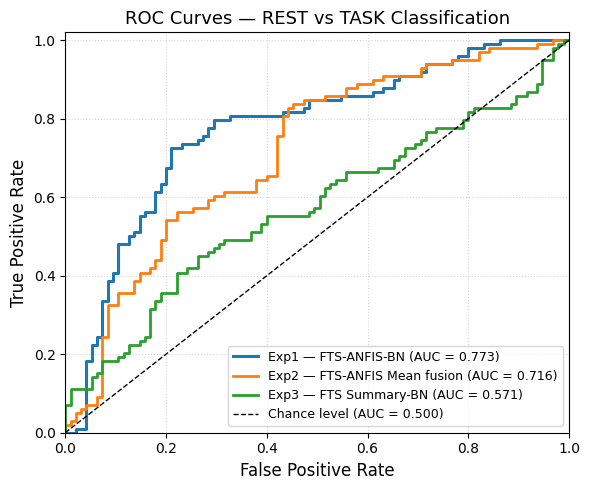

In [8]:
roc_png_path = RESULTS_DIR / "paper_roc_curves.png"

# Colour map — all experiments use solid lines, differentiated only by colour
_STYLE_MAP = {
    "Exp1": {"color": "#1f77b4", "linestyle": "-", "linewidth": 2.2},
    "Exp2": {"color": "#ff7f0e", "linestyle": "-", "linewidth": 2.0},
    "Exp3": {"color": "#2ca02c", "linestyle": "-", "linewidth": 2.0},
}

fig, ax = plt.subplots(figsize=(6, 5))
plotted = False

for _, row in results_df.iterrows():
    exp_label = row["Experiment"]
    raw       = raw_results[exp_label]
    y_true    = raw["y_test"]
    y_prob    = raw["test_post"]

    if y_prob is None:
        print(f"[{exp_label}] Skipping ROC — probability scores not available.")
        continue

    try:
        fpr, tpr, _ = roc_curve(y_true, y_prob, pos_label=1)
        auc_val     = roc_auc_score(y_true, y_prob)
    except ValueError as exc:
        print(f"[{exp_label}] ROC curve error: {exc}")
        continue

    style = _STYLE_MAP.get(exp_label, {})
    ax.plot(fpr, tpr,
            label=f"{exp_label} — {row['Configuration']} (AUC = {auc_val:.3f})",
            **style)
    plotted = True

if plotted:
    ax.plot([0, 1], [0, 1], "k--", linewidth=1.0, label="Chance level (AUC = 0.500)")
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate", fontsize=12)
    ax.set_title("ROC Curves — REST vs TASK Classification", fontsize=13)
    ax.legend(loc="lower right", fontsize=9)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.02])
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
    ax.grid(True, linestyle=":", alpha=0.5)
    fig.tight_layout()
    fig.savefig(roc_png_path, dpi=150, bbox_inches="tight")
    print(f"ROC curve saved to: {roc_png_path}")
    plt.show()
else:
    print("No ROC curves plotted — probability scores missing for all experiments.")
    plt.close(fig)


## Cell 9 — Confusion Matrices (aligned with Table 3)

Confusion matrices saved to: C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\results\paper_confusion_matrices.png


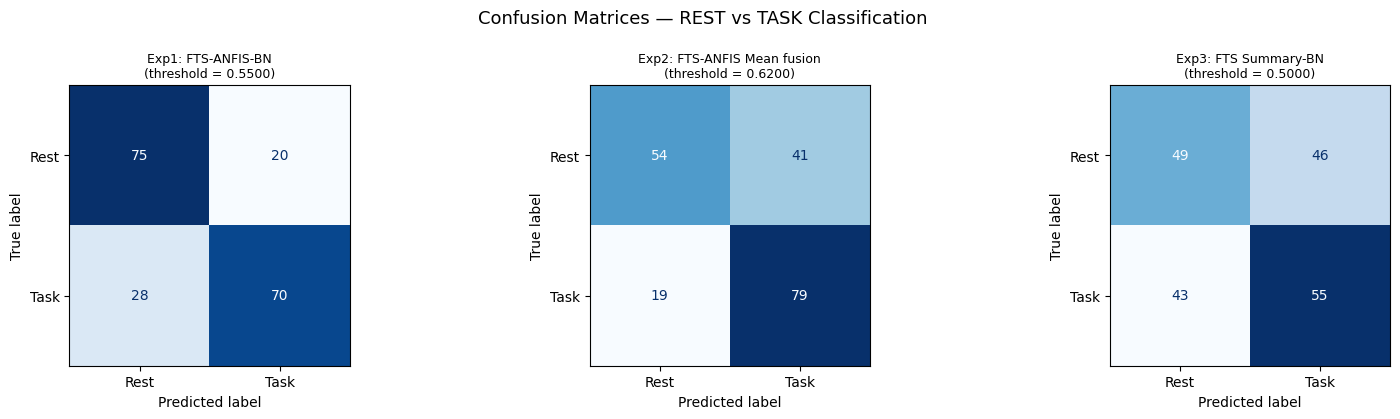


Confusion Matrix Metric Verification (vs Table 3)
Experiment  TN  FP  FN  TP  Accuracy  Precision  Recall  F1-score Matches Table 3
      Exp1  75  20  28  70    0.7513     0.7778  0.7143    0.7447             YES
      Exp2  54  41  19  79    0.6891     0.6583  0.8061    0.7248             YES
      Exp3  49  46  43  55    0.5389     0.5446  0.5612    0.5528             YES


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Guard: ensure cells 2–6 have been executed first.
_missing = [v for v in ("RESULTS_DIR", "PAPER_EXPERIMENTS", "raw_results", "results_df")
            if v not in globals()]
if _missing:
    raise RuntimeError(
        f"The following variables are not defined: {_missing}\n"
        "Please run cells 2–6 first (Setup → Helper Functions → Run Experiments)."
    )

cm_png_path = RESULTS_DIR / "paper_confusion_matrices.png"

# Expected values from Table 3 (used only for post-plot verification).
TABLE3_EXPECTED = {
    "Exp1": {"acc": 0.7513, "prec": 0.7778, "rec": 0.7143, "f1": 0.7447},
    "Exp2": {"acc": 0.6891, "prec": 0.6583, "rec": 0.8061, "f1": 0.7248},
    "Exp3": {"acc": 0.5389, "prec": 0.5446, "rec": 0.5612, "f1": 0.5528},
}
MATCH_TOL = 1e-4

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
verification_rows: list[dict] = []

for ax, exp_def in zip(axes, PAPER_EXPERIMENTS):
    label         = exp_def["label"]
    configuration = exp_def["configuration"]

    raw = raw_results[label]
    y_true = raw["y_test"]
    y_pred = raw["test_pred"]
    thr    = raw["best_thr"]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    acc  = float(accuracy_score(y_true, y_pred))
    prec = float(precision_score(y_true, y_pred, pos_label=1, zero_division=0))
    rec  = float(recall_score(y_true, y_pred,    pos_label=1, zero_division=0))
    f1v  = float(f1_score(y_true, y_pred,        pos_label=1, zero_division=0))

    exp_vals = TABLE3_EXPECTED[label]
    match = (
        abs(acc  - exp_vals["acc"])  <= MATCH_TOL and
        abs(prec - exp_vals["prec"]) <= MATCH_TOL and
        abs(rec  - exp_vals["rec"])  <= MATCH_TOL and
        abs(f1v  - exp_vals["f1"])   <= MATCH_TOL
    )
    if not match:
        print(f"[WARN] Confusion matrix metrics do not match Table 3 for {label}.")
        print(f"  threshold used : {thr:.6f}")
        print(f"  acc  : expected={exp_vals['acc']:.4f}, got={acc:.4f}")
        print(f"  prec : expected={exp_vals['prec']:.4f}, got={prec:.4f}")
        print(f"  rec  : expected={exp_vals['rec']:.4f}, got={rec:.4f}")
        print(f"  f1   : expected={exp_vals['f1']:.4f}, got={f1v:.4f}")

    verification_rows.append({
        "Experiment": label,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy":  round(acc,  4),
        "Precision": round(prec, 4),
        "Recall":    round(rec,  4),
        "F1-score":  round(f1v,  4),
        "Matches Table 3": "YES" if match else "NO",
    })

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Rest", "Task"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(
        f"{label}: {configuration}\n(threshold = {thr:.4f})",
        fontsize=9, pad=6,
    )

fig.suptitle("Confusion Matrices — REST vs TASK Classification", fontsize=13, y=1.02)
fig.tight_layout(pad=0.6, w_pad=0.3)
fig.subplots_adjust(wspace=0.8)
fig.savefig(cm_png_path, dpi=150, bbox_inches="tight")
print(f"Confusion matrices saved to: {cm_png_path}")
plt.show()

# ── Print verification table ───────────────────────────────────────────────────
print("\n" + "=" * 80)
print("Confusion Matrix Metric Verification (vs Table 3)")
print("=" * 80)
vdf = pd.DataFrame(verification_rows)
print(vdf.to_string(index=False))


## Cell 9 — Result Commentary

The following commentary summarises the experimental findings in paper style.

In [10]:
def _get(metric: str, exp: str) -> str:
    row = results_df[results_df["Experiment"] == exp].iloc[0]
    v   = row[metric]
    return f"{v:.4f}" if isinstance(v, float) else str(v)

commentary = f"""
Commentary (paper style)
========================

Table 3 summarises the classification performance of the three experimental
configurations evaluated under a subject-independent hold-out protocol with
5-fold GroupKFold cross-validation for threshold selection.

The full pipeline (Exp1: FTS-ANFIS-BN) achieves the highest test accuracy of
{_get('Test Accuracy', 'Exp1')} and an AUC of {_get('Test AUC', 'Exp1')},
demonstrating that the proposed three-stage architecture—Fuzzy Time-Series
encoding, ANFIS-based per-signal probability estimation, and Bayesian Network
fusion—effectively discriminates the TASK state from REST across unseen
subjects.

Comparing Exp1 with Exp2 (FTS-ANFIS Mean fusion, test accuracy =
{_get('Test Accuracy', 'Exp2')}, AUC = {_get('Test AUC', 'Exp2')}),
which replaces the Bayesian Network stage with a simple mean fusion of the
four ANFIS outputs, reveals a consistent performance drop. This gap highlights
the contribution of the BN stage: by modelling the conditional dependencies
between physiological signals given the cognitive state, the BN achieves a
more principled integration of multi-modal evidence that cannot be recovered
by naive averaging.

Comparing Exp1 with Exp3 (FTS Summary-BN, test accuracy =
{_get('Test Accuracy', 'Exp3')}, AUC = {_get('Test AUC', 'Exp3')}),
which bypasses the ANFIS stage and feeds compact FTS summary scores directly
into the BN, yields a further performance degradation. This result underlines
the importance of the ANFIS stage: the fuzzy inference system learns
non-linear mappings from FTS features to per-signal posterior probabilities,
producing richer signal-level evidence than a fixed hand-crafted summary
statistic.

Taken together, the ablation results validate each stage of the FTS-ANFIS-BN
pipeline: the AUC values above 0.5 across all configurations confirm that FTS
features carry meaningful REST/TASK discriminative information, while the
staged improvements from Exp3 → Exp2 → Exp1 demonstrate the additive value
of both the ANFIS and BN components.
"""

print(commentary)



Commentary (paper style)

Table 3 summarises the classification performance of the three experimental
configurations evaluated under a subject-independent hold-out protocol with
5-fold GroupKFold cross-validation for threshold selection.

The full pipeline (Exp1: FTS-ANFIS-BN) achieves the highest test accuracy of
0.7513 and an AUC of 0.7734,
demonstrating that the proposed three-stage architecture—Fuzzy Time-Series
encoding, ANFIS-based per-signal probability estimation, and Bayesian Network
fusion—effectively discriminates the TASK state from REST across unseen
subjects.

Comparing Exp1 with Exp2 (FTS-ANFIS Mean fusion, test accuracy =
0.6891, AUC = 0.7158),
which replaces the Bayesian Network stage with a simple mean fusion of the
four ANFIS outputs, reveals a consistent performance drop. This gap highlights
the contribution of the BN stage: by modelling the conditional dependencies
between physiological signals given the cognitive state, the BN achieves a
more principled integrati